<a href="https://colab.research.google.com/github/apeksha300/Unsupervised_Model/blob/main/Unsupervised_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris, load_breast_cancer

from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans, AgglomerativeClustering

from sklearn.decomposition import PCA

from sklearn.metrics import (
    silhouette_score,
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve
)

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

iris = load_iris(as_frame=True)

iris_df = iris.data

print("First five rows of the dataset:")
display(iris_df.head())

print("\nDataset shape:", iris_df.shape)

print("\nFeatures:")
print(iris.feature_names)

print("\nTarget names:")
print(iris.target_names)

print("\nMissing values:")
print(iris_df.isnull().sum())

print("\nDuplicate records:", iris_df.duplicated().sum())


First five rows of the dataset:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Dataset shape: (150, 4)

Features:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target names:
['setosa' 'versicolor' 'virginica']

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

Duplicate records: 1


In [3]:

iris_labels = iris.target.copy()

iris_clean = iris_df.drop_duplicates().copy()

iris_labels = iris_labels.loc[iris_clean.index]

print("Dataset shape after removing duplicates:",
      iris_clean.shape)

print("Duplicate records after cleaning:",
      iris_clean.duplicated().sum())

scaler = StandardScaler()

iris_scaled = scaler.fit_transform(iris_clean)

iris_scaled_df = pd.DataFrame(
    iris_scaled,
    columns=iris_clean.columns,
    index=iris_clean.index
)

print("\nFirst five rows after scaling:")
display(iris_scaled_df.head())

print("\nMean of scaled features:")
print(iris_scaled_df.mean().round(2))

print("\nStandard deviation of scaled features:")
print(iris_scaled_df.std().round(2))


Dataset shape after removing duplicates: (149, 4)
Duplicate records after cleaning: 0

First five rows after scaling:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.898033,1.012401,-1.333255,-1.308624
1,-1.139562,-0.137353,-1.333255,-1.308624
2,-1.381091,0.322549,-1.390014,-1.308624
3,-1.501855,0.092598,-1.276496,-1.308624
4,-1.018798,1.242352,-1.333255,-1.308624



Mean of scaled features:
sepal length (cm)    0.0
sepal width (cm)     0.0
petal length (cm)   -0.0
petal width (cm)    -0.0
dtype: float64

Standard deviation of scaled features:
sepal length (cm)    1.0
sepal width (cm)     1.0
petal length (cm)    1.0
petal width (cm)     1.0
dtype: float64


In [4]:

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(iris_scaled)

iris_clean["KMeans_Cluster"] = kmeans_labels

print("First 10 cluster assignments:")
print(kmeans_labels[:10])

print("\nNumber of records in each cluster:")
print(iris_clean["KMeans_Cluster"].value_counts().sort_index())

silhouette_kmeans = silhouette_score(
    iris_scaled,
    kmeans_labels
)

print("\nK-Means Silhouette Score:",
      round(silhouette_kmeans, 4))


First 10 cluster assignments:
[1 1 1 1 1 1 1 1 1 1]

Number of records in each cluster:
KMeans_Cluster
0    52
1    50
2    47
Name: count, dtype: int64

K-Means Silhouette Score: 0.4607


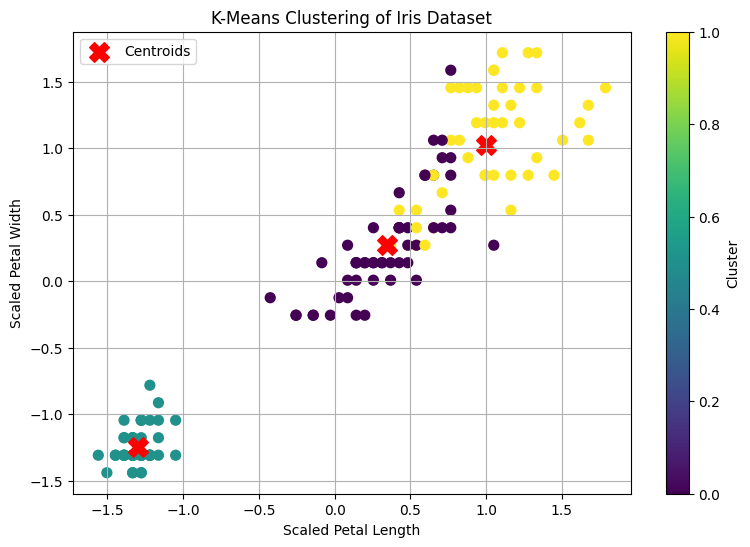

In [5]:

plt.figure(figsize=(9, 6))

plt.scatter(
    iris_scaled[:, 2],
    iris_scaled[:, 3],
    c=kmeans_labels,
    cmap="viridis",
    s=50
)

plt.scatter(
    kmeans.cluster_centers_[:, 2],
    kmeans.cluster_centers_[:, 3],
    color="red",
    marker="X",
    s=200,
    label="Centroids"
)

plt.title("K-Means Clustering of Iris Dataset")
plt.xlabel("Scaled Petal Length")
plt.ylabel("Scaled Petal Width")
plt.legend()
plt.colorbar(label="Cluster")
plt.grid(True)
plt.show()


In [6]:

hierarchical = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(iris_scaled)

iris_clean["Hierarchical_Cluster"] = hierarchical_labels

print("First 10 cluster assignments:")
print(hierarchical_labels[:10])

print("\nNumber of records in each cluster:")
print(
    pd.Series(hierarchical_labels)
    .value_counts()
    .sort_index()
)

silhouette_hierarchical = silhouette_score(
    iris_scaled,
    hierarchical_labels
)

print("\nHierarchical Clustering Silhouette Score:",
      round(silhouette_hierarchical, 4))


First 10 cluster assignments:
[1 1 1 1 1 1 1 1 1 1]

Number of records in each cluster:
0    70
1    49
2    30
Name: count, dtype: int64

Hierarchical Clustering Silhouette Score: 0.4498


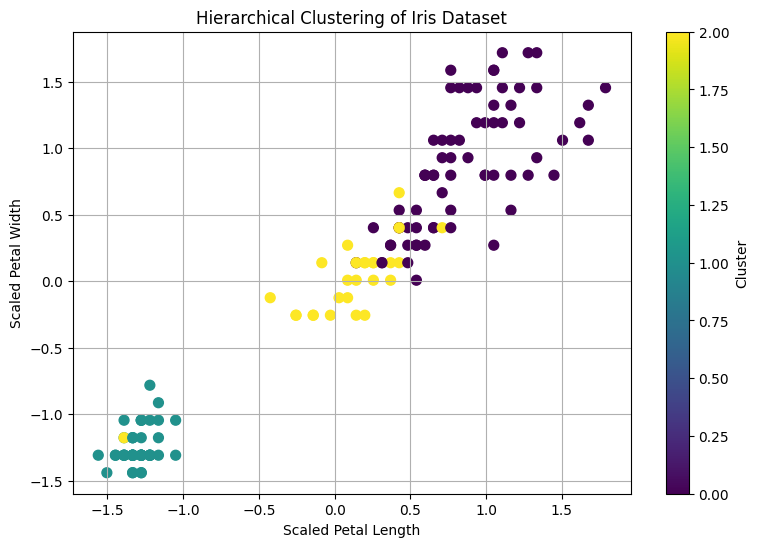

In [7]:

plt.figure(figsize=(9, 6))

plt.scatter(
    iris_scaled[:, 2],
    iris_scaled[:, 3],
    c=hierarchical_labels,
    cmap="viridis",
    s=50
)

plt.title("Hierarchical Clustering of Iris Dataset")
plt.xlabel("Scaled Petal Length")
plt.ylabel("Scaled Petal Width")

plt.colorbar(label="Cluster")
plt.grid(True)
plt.show()


In [8]:

pca = PCA(n_components=2)

iris_pca = pca.fit_transform(iris_scaled)

pca_df = pd.DataFrame(
    iris_pca,
    columns=["Principal Component 1", "Principal Component 2"]
)

print("First five rows after PCA:")
display(pca_df.head())

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_.round(4))

total_variance = sum(pca.explained_variance_ratio_)

print("\nTotal variance retained:",
      round(total_variance * 100, 2), "%")


First five rows after PCA:


,Principal Component 1,Principal Component 2
0,-2.252692,0.479299
1,-2.071004,-0.674234
2,-2.353147,-0.340442
3,-2.288762,-0.595441
4,-2.377294,0.646885



Explained variance ratio:
[0.7299 0.2286]

Total variance retained: 95.85 %


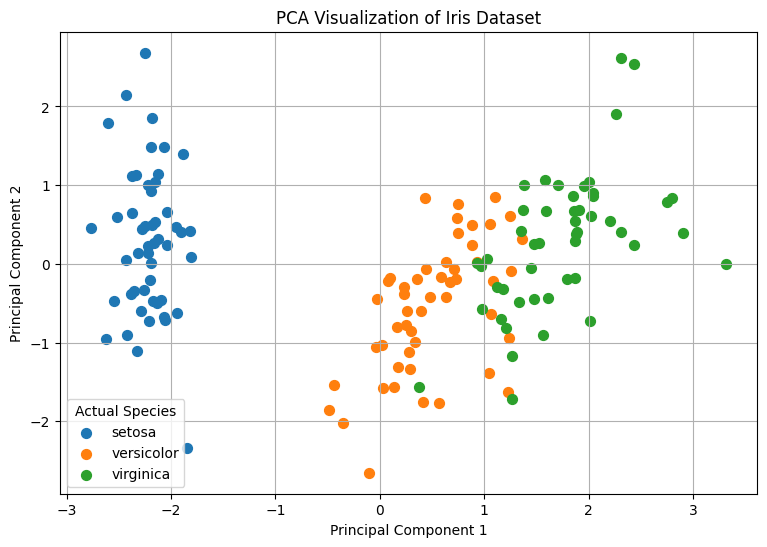

In [10]:

plt.figure(figsize=(9, 6))

for species_id, species_name in enumerate(iris.target_names):

    mask = (iris_labels.values == species_id)

    plt.scatter(
        pca_df.loc[mask, "Principal Component 1"],
        pca_df.loc[mask, "Principal Component 2"],
        label=species_name,
        s=50
    )

plt.title("PCA Visualization of Iris Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Actual Species")
plt.grid(True)
plt.show()


In [11]:
cancer = load_breast_cancer(as_frame=True)

cancer_df = cancer.data
cancer_target = cancer.target

print("First five rows of the dataset:")
display(cancer_df.head())

print("\nDataset shape:", cancer_df.shape)

print("\nNumber of features:", cancer_df.shape[1])

print("\nTarget names:")
print(cancer.target_names)

print("\nMissing values:")
print(cancer_df.isnull().sum().sum())

print("\nDuplicate records:", cancer_df.duplicated().sum())

print("\nClass distribution:")
print(cancer_target.value_counts().sort_index())


First five rows of the dataset:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Dataset shape: (569, 30)

Number of features: 30

Target names:
['malignant' 'benign']

Missing values:
0

Duplicate records: 0

Class distribution:
target
0    212
1    357
Name: count, dtype: int64


In [12]:
cancer_y = (cancer_target == 0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    cancer_df,
    cancer_y,
    test_size=0.20,
    random_state=42,
    stratify=cancer_y
)

cancer_scaler = StandardScaler()

X_train_scaled = cancer_scaler.fit_transform(X_train)
X_test_scaled = cancer_scaler.transform(X_test)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

print("\nMean of first scaled feature:",
      round(X_train_scaled[:, 0].mean(), 2))

print("Standard deviation of first scaled feature:",
      round(X_train_scaled[:, 0].std(), 2))


Training data shape: (455, 30)
Testing data shape: (114, 30)

Training class distribution:
target
0    285
1    170
Name: count, dtype: int64

Testing class distribution:
target
0    72
1    42
Name: count, dtype: int64

Mean of first scaled feature: -0.0
Standard deviation of first scaled feature: 1.0


In [13]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train_scaled, y_train)

y_pred = logistic_model.predict(X_test_scaled)

y_prob = logistic_model.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression trained successfully!")

print("\nFirst 10 actual values:")
print(y_test.values[:10])

print("\nFirst 10 predicted values:")
print(y_pred[:10])


Logistic Regression trained successfully!

First 10 actual values:
[0 1 0 1 0 0 1 0 0 0]

First 10 predicted values:
[0 1 0 1 1 0 1 0 0 0]


In [14]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

f1 = f1_score(y_test, y_pred)

roc_auc = roc_auc_score(y_test, y_prob)

print("\nModel Evaluation Results:")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Benign", "Malignant"]
))


Confusion Matrix:
[[71  1]
 [ 3 39]]

Model Evaluation Results:
Accuracy: 0.9649
Precision: 0.975
Recall: 0.9286
F1 Score: 0.9512
ROC-AUC: 0.996

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



<Figure size 600x500 with 0 Axes>

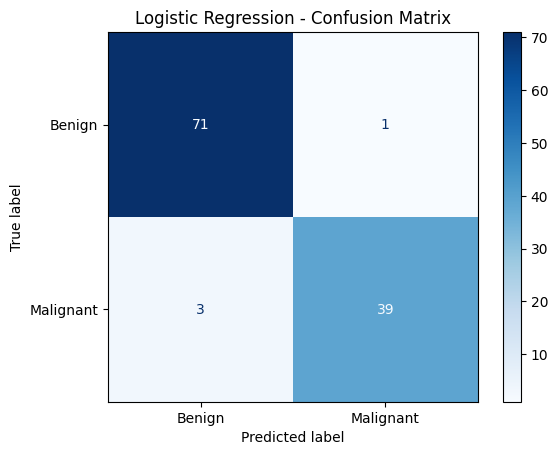

<Figure size 700x500 with 0 Axes>

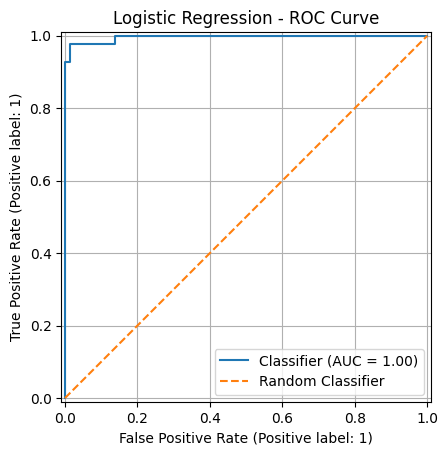

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

plt.figure(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Benign", "Malignant"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

plt.figure(figsize=(7, 5))

RocCurveDisplay.from_predictions(
    y_test,
    y_prob
)

plt.plot([0, 1], [0, 1], linestyle="--",
         label="Random Classifier")

plt.title("Logistic Regression - ROC Curve")
plt.legend()
plt.grid(True)
plt.show()


In [16]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    cv_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

cv_recall_scores = cross_val_score(
    cv_model,
    X_train,
    y_train,
    cv=cv,
    scoring="recall"
)

print("Accuracy scores for each fold:")
print(cv_scores.round(4))

print("\nAverage cross-validation accuracy:",
      round(cv_scores.mean(), 4))

print("\nStandard deviation of accuracy:",
      round(cv_scores.std(), 4))

print("\nRecall scores for each fold:")
print(cv_recall_scores.round(4))

print("\nAverage cross-validation recall:",
      round(cv_recall_scores.mean(), 4))


Accuracy scores for each fold:
[0.956 0.967 1.    0.978 0.967]

Average cross-validation accuracy: 0.9736

Standard deviation of accuracy: 0.0149

Recall scores for each fold:
[0.8824 0.9706 1.     0.9412 0.9706]

Average cross-validation recall: 0.9529


In [17]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate, StratifiedKFold

cv_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    cv_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ]
)

print("5-Fold Cross-Validation Results")

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:

    scores = cv_results["test_" + metric]

    print("\n", metric.upper())
    print("Fold scores:", scores.round(4))
    print("Average:", round(scores.mean(), 4))
    print("Standard deviation:", round(scores.std(), 4))


5-Fold Cross-Validation Results

 ACCURACY
Fold scores: [0.956 0.967 1.    0.978 0.967]
Average: 0.9736
Standard deviation: 0.0149

 PRECISION
Fold scores: [1.     0.9429 1.     1.     0.9429]
Average: 0.9771
Standard deviation: 0.028

 RECALL
Fold scores: [0.8824 0.9706 1.     0.9412 0.9706]
Average: 0.9529
Standard deviation: 0.0399

 F1
Fold scores: [0.9375 0.9565 1.     0.9697 0.9565]
Average: 0.964
Standard deviation: 0.0207

 ROC_AUC
Fold scores: [0.9948 0.999  1.     0.9871 0.9979]
Average: 0.9958
Standard deviation: 0.0047


In [18]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

tuning_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"]
}

tuning_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    cv=tuning_cv,
    scoring="recall",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Recall:")
print(round(grid_search.best_score_, 4))

print("\nTotal combinations tested:")
print(len(grid_search.cv_results_["params"]))


Best Parameters:
{'model__C': 1, 'model__class_weight': 'balanced'}

Best Cross-Validation Recall:
0.9588

Total combinations tested:
10


In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

best_model = grid_search.best_estimator_

tuned_pred = best_model.predict(X_test)

tuned_prob = best_model.predict_proba(X_test)[:, 1]

tuned_accuracy = accuracy_score(y_test, tuned_pred)
tuned_precision = precision_score(y_test, tuned_pred)
tuned_recall = recall_score(y_test, tuned_pred)
tuned_f1 = f1_score(y_test, tuned_pred)
tuned_roc_auc = roc_auc_score(y_test, tuned_prob)

print("Tuned Model Confusion Matrix:")
print(confusion_matrix(y_test, tuned_pred))

print("\nTuned Logistic Regression Results:")
print("Accuracy:", round(tuned_accuracy, 4))
print("Precision:", round(tuned_precision, 4))
print("Recall:", round(tuned_recall, 4))
print("F1 Score:", round(tuned_f1, 4))
print("ROC-AUC:", round(tuned_roc_auc, 4))

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
    "Original Model": [
        accuracy, precision, recall, f1, roc_auc
    ],
    "Tuned Model": [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1,
        tuned_roc_auc
    ]
})

print("\nOriginal vs Tuned Model Comparison:")
display(comparison.round(4))


Tuned Model Confusion Matrix:
[[71  1]
 [ 2 40]]

Tuned Logistic Regression Results:
Accuracy: 0.9737
Precision: 0.9756
Recall: 0.9524
F1 Score: 0.9639
ROC-AUC: 0.9954

Original vs Tuned Model Comparison:


,Metric,Original Model,Tuned Model
0,Accuracy,0.9649,0.9737
1,Precision,0.9750,0.9756
2,Recall,0.9286,0.9524
3,F1 Score,0.9512,0.9639
4,ROC-AUC,0.9960,0.9954


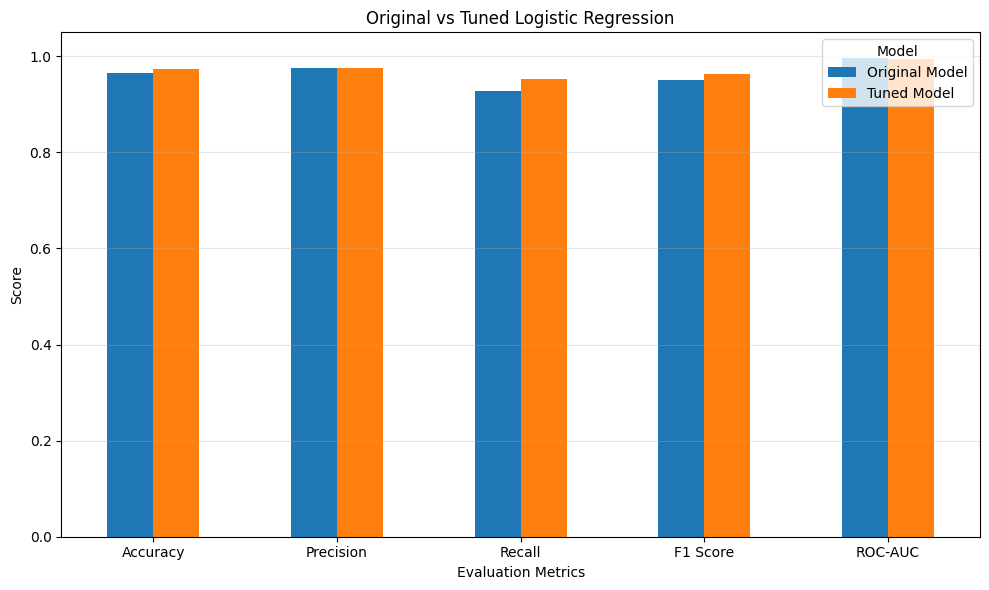

Model comparison CSV saved successfully!


In [20]:
comparison_plot = comparison.set_index("Metric")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Original vs Tuned Logistic Regression")
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

comparison.to_csv(
    "original_vs_tuned_model_comparison.csv",
    index=False
)

print("Model comparison CSV saved successfully!")


In [22]:
import joblib
import pandas as pd

iris_results = iris_clean.copy()

iris_results["Actual_Species"] = iris_labels.map(
    dict(enumerate(iris.target_names))
)

iris_results["PCA_Component_1"] = iris_pca[:, 0]
iris_results["PCA_Component_2"] = iris_pca[:, 1]

iris_results.to_csv("iris_clustering_results.csv", index=False)


clustering_comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "Hierarchical Clustering"],
    "Number_of_Clusters": [3, 3],
    "Silhouette_Score": [
        silhouette_kmeans,
        silhouette_hierarchical
    ]
})

clustering_comparison.to_csv(
    "clustering_comparison.csv", index=False
)


comparison.to_csv(
    "original_vs_tuned_model_comparison.csv",
    index=False
)



cv_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    "Mean": [
        cv_results["test_accuracy"].mean(),
        cv_results["test_precision"].mean(),
        cv_results["test_recall"].mean(),
        cv_results["test_f1"].mean(),
        cv_results["test_roc_auc"].mean()
    ],
    "Standard_Deviation": [
        cv_results["test_accuracy"].std(),
        cv_results["test_precision"].std(),
        cv_results["test_recall"].std(),
        cv_results["test_f1"].std(),
        cv_results["test_roc_auc"].std()
    ]
})

cv_summary.to_csv("cross_validation_results.csv", index=False)



joblib.dump(kmeans, "kmeans_model.pkl")
joblib.dump(hierarchical, "hierarchical_model.pkl")
joblib.dump(pca, "pca_model.pkl")
joblib.dump(scaler, "iris_scaler.pkl")
joblib.dump(best_model, "tuned_logistic_regression.pkl")



import os

required_files = [
    "iris_clustering_results.csv",
    "clustering_comparison.csv",
    "original_vs_tuned_model_comparison.csv",
    "cross_validation_results.csv",
    "kmeans_model.pkl",
    "hierarchical_model.pkl",
    "pca_model.pkl",
    "iris_scaler.pkl",
    "tuned_logistic_regression.pkl"
]

print("WEEK 3 Unsupervised Model")

for file in required_files:
    if os.path.exists(file):
        print("FOUND:", file)
    else:
        print("MISSING:", file)

print("\nAll project files checked")


WEEK 3 Unsupervised Model
FOUND: iris_clustering_results.csv
FOUND: clustering_comparison.csv
FOUND: original_vs_tuned_model_comparison.csv
FOUND: cross_validation_results.csv
FOUND: kmeans_model.pkl
FOUND: hierarchical_model.pkl
FOUND: pca_model.pkl
FOUND: iris_scaler.pkl
FOUND: tuned_logistic_regression.pkl

All project files checked!
